## P03  My First Market Predictor

### Question de recherche

À la clôture d’une semaine, peut-on prédire si SPY clôturera plus haut la semaine suivante à partir des rendements passés ?

Dans P02, j’ai testé si le signe du mois précédent donnait une indication sur le mois suivant. Ici, je passe à l’échelle hebdomadaire et je teste deux modèles qui combinent plusieurs informations.

### Données et cible

Je pars des clôtures journalières ajustées de SPY et je garde la dernière clôture de chaque semaine complète. Chaque ligne correspond à la semaine où j’émets la prédiction.

- **Entrées du modèle** — Le rendement de la semaine courante, le rendement cumulé des quatre dernières semaines et l’écart-type des quatre derniers rendements hebdomadaires. Ces trois valeurs sont connues à la clôture du signal.
- **Cible** — `1` si la clôture de la semaine suivante est supérieure à celle de la semaine courante, `0` si elle est égale ou inférieure.

### Expérience

J’entraîne une **régression logistique** et une **forêt aléatoire** sur les semaines les plus anciennes. Je les évalue sur les semaines les plus récentes, mises de côté pour le test.

Ma **référence** prédit toujours la classe la plus fréquente dans les données d’entraînement. Je compare les trois approches sur les mêmes semaines de test, en regardant la proportion de prédictions correctes et les erreurs sur chaque classe.

Je conserve les dates et les probabilités de hausse produites sur le test pour les réutiliser dans P04.

In [21]:
import yfinance as yf
import pandas as pd
import numpy
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

In [2]:
SPY = yf.download("SPY",start="2010-01-05",end="2026-10-31",interval="1wk",auto_adjust=True)

[*********************100%***********************]  1 of 1 completed


In [3]:
#RENDEMENTS = (SPY['Close'] / SPY['Close'].shift(1)) - 1
RENDEMENTS  = SPY['Close'].pct_change()
RENDEMENTS = RENDEMENTS.rename(columns={"SPY": "rendement_w"})

RENDEMENTS['rendement_w1'] = RENDEMENTS['rendement_w'].shift(-1)
RENDEMENTS = RENDEMENTS.dropna(subset=["rendement_w1"])
RENDEMENTS = RENDEMENTS.dropna(subset=["rendement_w"])

print(RENDEMENTS)

Ticker      rendement_w  rendement_w1
Date                                 
2010-01-11    -0.008117     -0.038983
2010-01-18    -0.038983     -0.016665
2010-01-25    -0.016665     -0.006798
2010-02-01    -0.006798      0.012939
2010-02-08     0.012939      0.028693
...                 ...           ...
2026-09-21     0.012682     -0.002217
2026-09-28    -0.002217      0.011603
2026-10-05     0.011603     -0.019677
2026-10-12    -0.019677     -0.004297
2026-10-19    -0.004297     -0.005592

[876 rows x 2 columns]


In [4]:
RENDEMENTS_W4  = SPY['Close'].pct_change(periods=4)


### Volatilité glissante sur quatre semaines

La volatilité est l’écart-type des quatre derniers rendements hebdomadaires, semaine courante incluse.

$$
s = \sqrt{\frac{\sum_{i=1}^{4}(r_i-\bar{r})^2}{4-1}}
\qquad
\bar{r} = \frac{r_1+r_2+r_3+r_4}{4}
$$

- $r_i$ désigne le rendement de la semaine $i$ dans la fenêtre.
- $\bar{r}$ est la moyenne des quatre rendements.
- $s$ mesure à quel point ces rendements s’écartent de leur moyenne.

Pour calculer $s$, je soustrais la moyenne à chaque rendement, j’élève les écarts au carré, je les additionne, je divise par $3$, puis je prends la racine carrée. Je répète ce calcul à chaque semaine en faisant glisser la fenêtre d’une semaine.


In [5]:
VOLATILITE_GLISSANTE_W4 = RENDEMENTS['rendement_w'].rolling(4).std()
print(VOLATILITE_GLISSANTE_W4)

Date
2010-01-11         NaN
2010-01-18         NaN
2010-01-25         NaN
2010-02-01    0.014885
2010-02-08    0.021589
                ...   
2026-09-21    0.008463
2026-09-28    0.008649
2026-10-05    0.007948
2026-10-12    0.015123
2026-10-19    0.012806
Freq: W-MON, Name: rendement_w, Length: 876, dtype: float64


In [6]:
DATA = RENDEMENTS.copy()
DATA['rendements_w4'] = RENDEMENTS_W4
DATA['volat_glissante_w4'] = VOLATILITE_GLISSANTE_W4
DATA['cible'] =  RENDEMENTS['rendement_w1'] > 0 

DATA = DATA.dropna(subset=['rendements_w4'])
DATA = DATA.dropna(subset=['volat_glissante_w4'])

In [7]:
print(DATA)

Ticker      rendement_w  rendement_w1  rendements_w4  volat_glissante_w4  \
Date                                                                       
2010-02-01    -0.006798      0.012939      -0.069041            0.014885   
2010-02-08     0.012939      0.028693      -0.049278            0.021589   
2010-02-15     0.028693     -0.003599       0.017672            0.020266   
2010-02-22    -0.003599      0.031696       0.031194            0.016391   
2010-03-01     0.031696      0.010591       0.071161            0.016256   
...                 ...           ...            ...                 ...   
2026-09-21     0.012682     -0.002217       0.005089            0.008463   
2026-09-28    -0.002217      0.011603       0.001767            0.008649   
2026-10-05     0.011603     -0.019677       0.021214            0.007948   
2026-10-12    -0.019677     -0.004297       0.002048            0.015123   
2026-10-19    -0.004297     -0.005592      -0.014753            0.012806   

Ticker     

In [8]:
# Dataframe pour l'entrainement puis pour le test

train = DATA.loc[:"2023--12-18"]
test = DATA.loc["2024-01-01":]

X_train = train[["rendement_w","rendements_w4","volat_glissante_w4"]]
Y_train = train["cible"]

X_test = test[["rendement_w","rendements_w4","volat_glissante_w4"]]
Y_test = test["cible"]

print(X_train.shape)
print(X_test.shape)


(725, 3)
(147, 3)


In [9]:
Y_test.mean()

np.float64(0.5782312925170068)

In [10]:
modele_logistique = LogisticRegression()
modele_logistique.fit(X_train,Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [29]:
probas = modele_logistique.predict(X_test) 

In [30]:
random_forest = RandomForestClassifier(random_state=42)
random_forest.fit(X_train,Y_train)
predictions_foret = random_forest.predict(X_test)
print(f"{(predictions_foret == Y_test).mean():.2%}")
confusion_matrix(Y_test, predictions_foret, labels=[False, True])

48.98%


array([[12, 50],
       [25, 60]])

Text(0, 0.5, 'Taux de bonnes prédictions (%)')

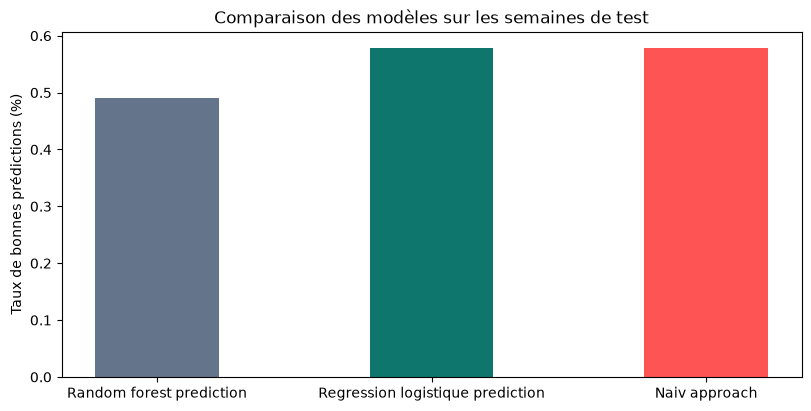

In [37]:
prediction_random_forest = (predictions_foret == Y_test).mean()
prediction_regresion_logistique = (probas == Y_test).mean()


fg, ax = plt.subplots(figsize=(8,4),layout="constrained")
ax.bar(["Random forest prediction","Regression logistique prediction","Naiv approach"],[prediction_random_forest,prediction_regresion_logistique,Y_test.mean()],width=0.45,color=["#64748B", "#0F766E","#FF1111B7"])
ax.set_title("Comparaison des modèles sur les semaines de test")
ax.set_ylabel("Taux de bonnes prédictions (%)")

In [40]:
random_forest.classes_

array([False,  True])

In [48]:
resultat_test = test.copy()
resultat_test["proba_hausse_foret"] = random_forest.predict_proba(X_test)[:, 1]
resultat_test["prediction_random_forest"] = random_forest.predict(X_test)
resultat_test["proba_hausse_logistique"] = modele_logistique.predict_proba(X_test)[:, 1]
resultat_test["prediction_regression_logistique"] =  modele_logistique.predict(X_test)
resultat_test


Ticker,rendement_w,rendement_w1,rendements_w4,volat_glissante_w4,cible,proba_hausse_foret,prediction_random_forest,proba_hausse_logistique,prediction_regression_logistique
Date,,,,,,,,,
2024-01-01,-0.015548,0.018721,0.020898,0.016348,True,0.63,True,0.590944,True
2024-01-08,0.018721,0.012063,0.015661,0.014447,True,0.52,True,0.589091,True
2024-01-15,0.012063,0.010323,0.018537,0.014857,True,0.63,True,0.589330,True
2024-01-22,0.010323,0.014239,0.025457,0.015066,True,0.52,True,0.588992,True
2024-01-29,0.014239,0.013856,0.056484,0.003629,True,0.48,False,0.587229,True
...,...,...,...,...,...,...,...,...,...
2026-09-21,0.012682,-0.002217,0.005089,0.008463,False,0.69,True,0.590430,True
2026-09-28,-0.002217,0.011603,0.001767,0.008649,True,0.68,True,0.591622,True
2026-10-05,0.011603,-0.019677,0.021214,0.007948,False,0.70,True,0.589487,True
